In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

In [2]:
base_path = r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\COVIDGR 1.0"

In [3]:
for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for f in files[:10]:
        print(f"{indent}    {f}")

    if len(files) > 10:
        print(f"{indent}    ... ({len(files)} files total)")

COVIDGR 1.0/
    desktop.ini
    severity.csv
    COVIDGR_1.0/
        desktop.ini
        N/
            00535c36caec75964ce74fc33d82d909.jpg
            0274491805b1da9656246df7e2c46ae8.jpg
            02fb3c2ce8607576ea2cb1eeb48408c8.jpg
            03465f96a67979c916a3646ef55157a4.jpg
            03ed1038301ccca1930523393736942d.jpg
            046e0e8bc1f6fa349e2921433c644475.jpg
            04e8fa1443349a1f8bd5261f46688652.jpg
            067f98b6e988c51a7b8437bf56e20869.jpg
            068478fc6ff804079e07aa9776a047c3.jpg
            0737776bebc9869ed9b29c6d53a8f5bd.jpg
            ... (427 files total)
        P/
            0021a3ef8340e3c2a599843997e94c76.jpg
            00960b9bd138047f3b868404aac7e531.jpg
            00b05aa3cb325265b9ded3f1a9f704c8.jpg
            00f9707e0de334db70a7924a9de98368.jpg
            0187b7c65ef69abd633c9bad6675dabf.jpg
            019ba8f463bf79db9875debbf9613b03.jpg
            01d381e16aa67898af213e64cb854dcf.jpg
            0212b1174ada9d99

In [4]:
extensions = []

for root, dirs, files in os.walk(base_path):
    for filename in files:
        ext = os.path.splitext(filename)[1].lower()

        if ext:
            extensions.append(ext)

print(Counter(extensions))

Counter({'.jpg': 852, '.ini': 6, '.csv': 6, '.md': 1})


In [5]:
positive_path = r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\COVIDGR 1.0\COVIDGR_1.0\P"
negative_path = r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\COVIDGR 1.0\COVIDGR_1.0\N"

folders = {
    "COVID Positive": positive_path,
    "COVID Negative": negative_path
}

for label, folder in folders.items():
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(".jpg")
    ]

    print(f"{label}: {len(images)} images")

COVID Positive: 426 images
COVID Negative: 426 images


In [6]:
for label, folder in folders.items():
    
    non_images = [
        f for f in os.listdir(folder)
        if not f.lower().endswith(".jpg")
    ]
    
    print(f"{label}: {non_images}")

COVID Positive: ['desktop.ini']
COVID Negative: ['desktop.ini']


In [7]:
# Create an empty list to store metadata for each image
image_info = []

# Loop through each class and its corresponding folder
for label, folder in folders.items():

    # Loop through every file in the class folder
    for filename in os.listdir(folder):

        # Skip non-JPG files (e.g. desktop.ini)
        if not filename.lower().endswith(".jpg"):
            continue

        # Create the full path to the image
        path = os.path.join(folder, filename)

        try:
            # Open the image and automatically close it afterwards
            with Image.open(path) as img:

                # Extract and store basic image metadata
                image_info.append({
                    "class": label,        # COVID Positive / COVID Negative
                    "filename": filename,  # Image filename
                    "width": img.width,    # Image width in pixels
                    "height": img.height,  # Image height in pixels
                    "mode": img.mode,      # Colour mode (e.g. RGB, L/grayscale)
                    "format": img.format   # Image format (e.g. JPEG)
                })

        # Report any image that cannot be opened/read
        except Exception as e:
            print(f"Error reading {filename}: {e}")

# Convert the collected image metadata into a Pandas DataFrame
image_df = pd.DataFrame(image_info)

# Display the first 5 rows to verify the result
image_df.head()

,class,filename,width,height,mode,format
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,2736,2448,L,JPEG
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,2724,2578,L,JPEG
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,2720,2218,L,JPEG
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,2728,2236,L,JPEG
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,2644,2131,L,JPEG


the width and height varies 

In [8]:
#check overall metadata summary

#show the toal number of images successfully read
print("Total readable images:", len(image_df))

#Count the number of images in each class
print("\nClass counts:")
print(image_df["class"].value_counts())

# Check which image formats are present in the dataset
print("\nImage formats:")
print(image_df["format"].value_counts())

# Check image colour modes separately for each class
# "L" means single-channel grayscale
print("\nImage modes by class:")
print(image_df.groupby(["class", "mode"]).size())



Total readable images: 852

Class counts:
class
COVID Positive    426
COVID Negative    426
Name: count, dtype: int64

Image formats:
format
JPEG    852
Name: count, dtype: int64

Image modes by class:
class           mode
COVID Negative  L       132
                RGB     294
COVID Positive  L       149
                RGB     277
dtype: int64


In [9]:
#resolution analysis

# Count the number of unique width × height combinations in each class
unique_resolutions = (
    image_df
    .groupby("class")
    .apply(
        lambda x: x[["width", "height"]]
        .drop_duplicates()
        .shape[0],
        include_groups=False
    )
)

print("Unique resolutions per class:")
print(unique_resolutions)

Unique resolutions per class:
class
COVID Negative    331
COVID Positive    272
dtype: int64


In [10]:
# Count how many images have each exact width × height combination
resolution_counts = (
    image_df
    .groupby(["class", "width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(["class", "count"], ascending=[True, False])
)

# Display the 10 most common resolutions from each class
top_resolutions = (
    resolution_counts
    .groupby("class")
    .head(10)
)

display(top_resolutions)

,class,width,height,count
13,COVID Negative,1920,1804,10
207,COVID Negative,2736,2864,9
325,COVID Negative,2840,2872,9
16,COVID Negative,2024,2020,6
12,COVID Negative,1920,1624,5
153,COVID Negative,2728,2848,5
183,COVID Negative,2732,2848,5
186,COVID Negative,2732,2860,5
205,COVID Negative,2736,2848,5
206,COVID Negative,2736,2860,5


In [11]:
# Create a new column called "aspect_ratio".
# For every image, divide its width by its height.
# Example: 2000 / 2000 = 1.0 (square image).
# Example: 3000 / 2000 = 1.5 (wider than tall).
image_df["aspect_ratio"] = image_df["width"] / image_df["height"]


# Select the "width", "height", and "aspect_ratio" columns from image_df.
# groupby("class") separates the calculations into COVID Positive and COVID Negative.
# describe() calculates summary statistics for each group:
# count = number of images
# mean = average
# std = standard deviation (how spread out the values are)
# min = smallest value
# 25% = first quartile
# 50% = median
# 75% = third quartile
# max = largest value
dimension_stats = (
    image_df
    .groupby("class")[["width", "height", "aspect_ratio"]]
    .describe()
)


# Display the resulting summary table.
display(dimension_stats)

width                                                          \
                count         mean         std    min     25%     50%     75%   
class                                                                           
COVID Negative  426.0  2613.338028  419.351122  492.0  2634.0  2732.0  2755.0   
COVID Positive  426.0  2570.394366  348.439904  514.0  2432.0  2724.0  2740.0   

                       height               ...                 aspect_ratio  \
                   max  count         mean  ...     75%     max        count   
class                                       ...                                
COVID Negative  3840.0  426.0  2494.518779  ...  2848.0  3056.0        426.0   
COVID Positive  3840.0  426.0  2429.307512  ...  2800.0  3000.0        426.0   

                                                                            \
                    mean       std       min       25%       50%       75%   
class                                                                        
COVID Negative  1.060439  0.159159  0.773876  0.960633  1.032188  1.104981   
COVID Positive  1.066791  0.123673  0.792079  0.982093  1.054468  1.138564   

                          
                     max  
class                     
COVID Negative  2.128603  
COVID Positive  2.364532  

[2 rows x 24 columns]

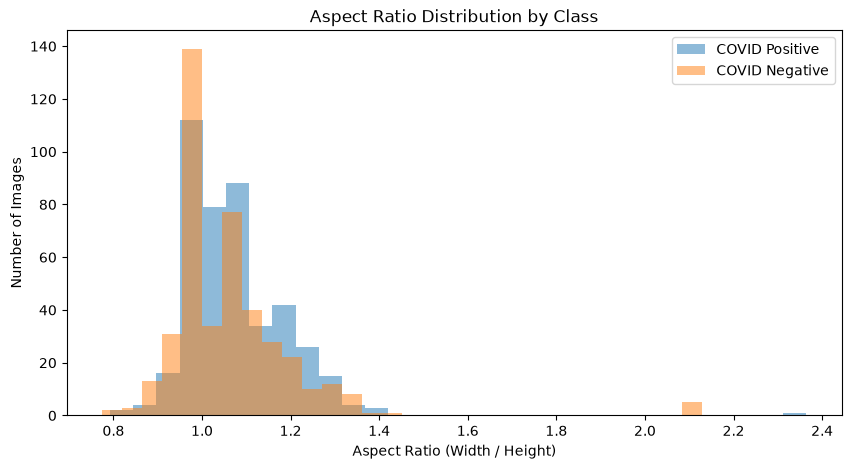

In [12]:
# Create a new figure that is 10 inches wide and 5 inches tall.
plt.figure(figsize=(10, 5))


# Loop through the two class names stored in the "class" column.
# unique() returns each class only once:
# COVID Positive and COVID Negative.
for label in image_df["class"].unique():

    # Select only the rows belonging to the current class.
    # Then select the "aspect_ratio" column from those rows.
    class_aspect_ratios = image_df[
        image_df["class"] == label
    ]["aspect_ratio"]

    # Plot a histogram showing the distribution of aspect ratios.
    # bins=30 divides the values into 30 ranges.
    # alpha=0.5 makes the histogram partially transparent,
    # allowing the two class distributions to overlap visibly.
    # label=label gives each class its name in the legend.
    plt.hist(
        class_aspect_ratios,
        bins=30,
        alpha=0.5,
        label=label
    )


# Label the horizontal axis.
plt.xlabel("Aspect Ratio (Width / Height)")


# Label the vertical axis.
plt.ylabel("Number of Images")


# Give the chart a descriptive title.
plt.title("Aspect Ratio Distribution by Class")


# Display a legend identifying Positive and Negative.
plt.legend()


# Display the completed chart.
plt.show()

Aspect ratio: Positive and negative classes show strongly overlapping aspect-ratio distributions, with most images approximately 0.9–1.3. A small number of extreme outliers are present (>2.0), but there is no obvious class-specific aspect-ratio bias. Will look at the outliers later

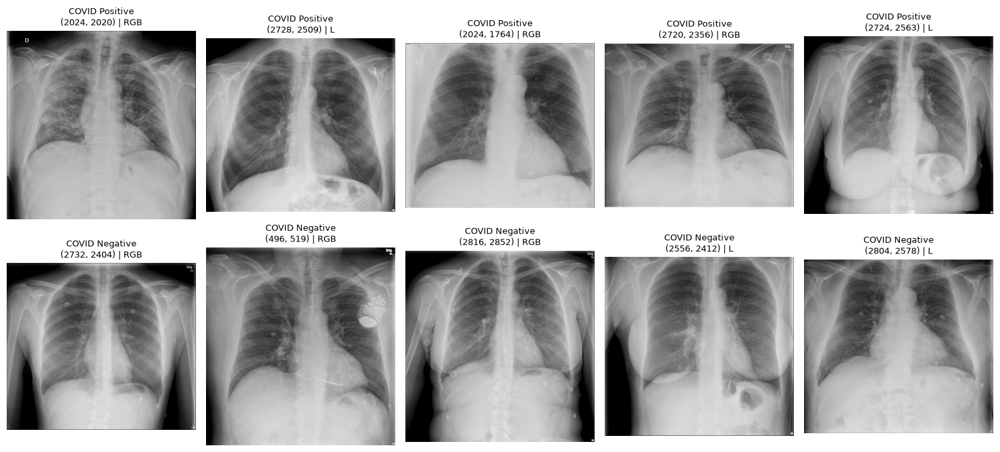

In [13]:
# Import Python's built-in random module so we can randomly select images
import random


# Create a figure containing 2 rows and 5 columns of plots.
# Row 1 will contain COVID Positive images.
# Row 2 will contain COVID Negative images.
# figsize controls the overall size of the displayed figure.
fig, axes = plt.subplots(2, 5, figsize=(15, 7))


# Loop through the folders dictionary.
# enumerate() also gives us a row number:
# row = 0 for the first class and row = 1 for the second class.
for row, (label, folder) in enumerate(folders.items()):

    # Get all filenames from the current class folder.
    # Only keep files ending in ".jpg" so desktop.ini is ignored.
    image_files = [
        filename
        for filename in os.listdir(folder)
        if filename.lower().endswith(".jpg")
    ]

    # Randomly select 5 different images from the current class.
    sample_files = random.sample(image_files, 5)

    # Loop through the 5 randomly selected filenames.
    # col gives the subplot column number from 0 to 4.
    for col, filename in enumerate(sample_files):

        # Combine the folder path and filename to create the full image path.
        image_path = os.path.join(folder, filename)

        # Open the selected image using PIL.
        img = Image.open(image_path)

        # Display the image in the appropriate subplot.
        # cmap="gray" displays it using a grayscale colour map.
        axes[row, col].imshow(img, cmap="gray")

        # Add the class, image dimensions and image mode above each image.
        # img.size returns (width, height).
        # img.mode tells us whether the original image is L, RGB, etc.
        axes[row, col].set_title(
            f"{label}\n{img.size} | {img.mode}",
            fontsize=9
        )

        # Remove the x-axis and y-axis because they are not useful for X-ray viewing.
        axes[row, col].axis("off")


# Automatically adjust spacing so titles/images do not overlap.
plt.tight_layout()

# Display the complete figure.
plt.show()

Visual inspection: Random samples from both classes show broadly similar chest positioning, framing and acquisition appearance. Variation in brightness, image dimensions and positioning is present, but no obvious class-specific visual artifact or cropping pattern was observed. Some images contain radiographic markers/external artifacts.

BRIGHTNESS AND CONTRAST ANALYSIS

In [14]:
# Create an empty list that will store the brightness and contrast
# measurements calculated for every image.
intensity_data = []


# Loop through the two classes and their corresponding folder paths.
# Example:
# label  = "COVID Positive"
# folder = path to the P folder
for label, folder in folders.items():

    # Loop through every file contained in the current class folder.
    for filename in os.listdir(folder):

        # Check whether the current file is a JPG image.
        # If it is not a JPG (for example desktop.ini), skip it.
        if not filename.lower().endswith(".jpg"):
            continue

        # Combine the folder path and filename to obtain the complete
        # path needed to open the image.
        path = os.path.join(folder, filename)

        # Open the current X-ray image using PIL.
        # "with" automatically closes the image after processing.
        with Image.open(path) as img:

            # Convert every image to grayscale ("L" mode).
            # This ensures RGB and grayscale images are analysed
            # using the same single-channel pixel representation.
            gray_img = img.convert("L")

            # Convert the PIL image into a NumPy array.
            # Each pixel now becomes a numerical value, usually 0-255.
            # 0 = black and 255 = white.
            pixel_array = np.array(gray_img)

            # Calculate and store statistics for the current image.
            intensity_data.append({

                # Store the class label so we can later compare
                # COVID Positive against COVID Negative.
                "class": label,

                # Store the filename so we can identify individual
                # images later if unusual values are found.
                "filename": filename,

                # Calculate the average pixel value across the image.
                # Higher values generally indicate a brighter image.
                "mean_intensity": pixel_array.mean(),

                # Calculate the standard deviation of pixel values.
                # A larger value generally means greater variation
                # between dark and bright pixels (higher contrast).
                "std_intensity": pixel_array.std(),

                # Record the darkest pixel value in the image.
                "min_intensity": pixel_array.min(),

                # Record the brightest pixel value in the image.
                "max_intensity": pixel_array.max()
            })


# Convert the list of dictionaries into a Pandas DataFrame.
# Each row represents one X-ray image.
intensity_df = pd.DataFrame(intensity_data)


# Display the first 5 rows to verify that the calculations worked.
intensity_df.head()

,class,filename,mean_intensity,std_intensity,min_intensity,max_intensity
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,143.321416,52.554923,0,255
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,140.917557,57.125726,0,255
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,93.147545,61.179093,0,255
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,145.049556,48.982005,0,255
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,132.490935,55.977132,0,244


In [15]:
# Group all images according to their class.
# Select only mean intensity (brightness) and standard deviation
# (our approximate contrast measurement).
intensity_summary = (
    intensity_df
    .groupby("class")[["mean_intensity", "std_intensity"]]

    # Calculate useful descriptive statistics for each class:
    # mean   = average value across all images
    # median = middle value, less affected by extreme images
    # std    = variation between images within that class
    # min    = lowest observed value
    # max    = highest observed value
    .agg(["mean", "median", "std", "min", "max"])
)


# Display the completed summary table.
display(intensity_summary)

mean_intensity                                                \
                         mean      median        std        min         max   
class                                                                         
COVID Negative     132.831148  134.357882  12.944357  52.199341  168.459180   
COVID Positive     135.483598  137.570369  13.964006  68.484477  192.547761   

               std_intensity                                             
                        mean     median       std        min        max  
class                                                                    
COVID Negative      59.12527  59.298909  6.932094  29.392956  85.461210  
COVID Positive      58.06990  57.455801  6.780304  43.577216  83.904064

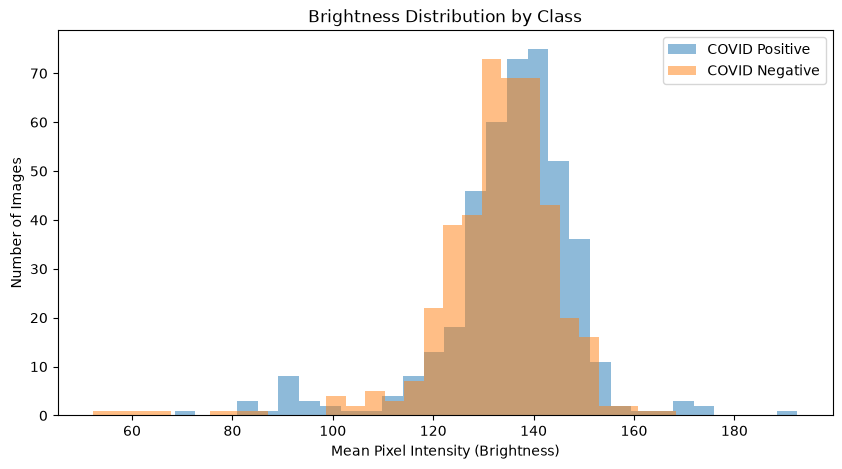

In [16]:
# Create a new figure for the brightness histogram.
plt.figure(figsize=(10, 5))


# Loop through each unique class in the intensity DataFrame.
for label in intensity_df["class"].unique():

    # Select only rows belonging to the current class,
    # then retrieve their mean pixel intensity values.
    brightness_values = intensity_df[
        intensity_df["class"] == label
    ]["mean_intensity"]

    # Plot the distribution of image brightness.
    # bins=30 divides the brightness range into 30 intervals.
    # alpha=0.5 makes the bars transparent so overlapping
    # distributions from the two classes remain visible.
    plt.hist(
        brightness_values,
        bins=30,
        alpha=0.5,
        label=label
    )


# Label the horizontal axis.
# Higher mean pixel intensity generally means a brighter image.
plt.xlabel("Mean Pixel Intensity (Brightness)")


# Label the vertical axis with the number of images in each bin.
plt.ylabel("Number of Images")


# Add a descriptive title.
plt.title("Brightness Distribution by Class")


# Add a legend identifying the two classes.
plt.legend()


# Display the completed histogram.
plt.show()

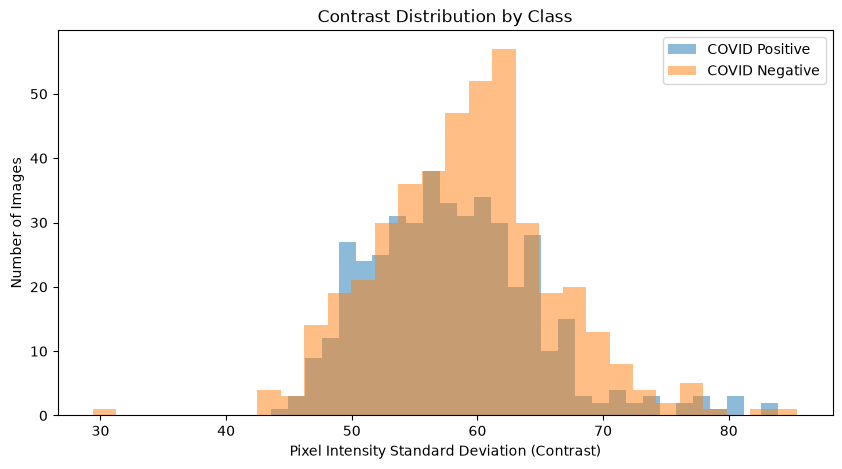

In [17]:
# Create a new figure for the contrast histogram.
plt.figure(figsize=(10, 5))


# Loop through each COVID class.
for label in intensity_df["class"].unique():

    # Select the pixel standard deviation values belonging
    # only to the current class.
    contrast_values = intensity_df[
        intensity_df["class"] == label
    ]["std_intensity"]

    # Plot the distribution of contrast measurements.
    # Higher standard deviation generally means that the image
    # contains a wider spread of dark and bright pixel values.
    plt.hist(
        contrast_values,
        bins=30,
        alpha=0.5,
        label=label
    )


# Label the horizontal axis.
plt.xlabel("Pixel Intensity Standard Deviation (Contrast)")


# Label the vertical axis.
plt.ylabel("Number of Images")


# Add a descriptive title.
plt.title("Contrast Distribution by Class")


# Display the class labels.
plt.legend()


# Display the completed histogram.
plt.show()

There is no major brightness/contrast separation between the classes.

Brightness: Strong overlap between COVID-positive and COVID-negative images. Mean intensity was 135.48 for positive and 132.83 for negative images. No major class-specific brightness bias observed, although several outliers are present.

Contrast: Strong overlap between classes. Mean pixel-intensity SD was 58.07 for positive and 59.13 for negative images, indicating no obvious class-specific contrast bias.

EXACT DUPLICATE DETECTION

In [18]:
# Import Python's hashlib library.
# It contains hashing algorithms such as MD5.
import hashlib


# Create an empty list to store the hash and metadata
# calculated for every image.
hash_records = []


# Loop through each class and its corresponding folder.
# label will be "COVID Positive" or "COVID Negative".
for label, folder in folders.items():

    # Loop through every file inside the current class folder.
    for filename in os.listdir(folder):

        # Only analyse JPG images.
        # This skips files such as desktop.ini.
        if not filename.lower().endswith(".jpg"):
            continue

        # Combine the folder path and filename to create
        # the complete path to the current image.
        path = os.path.join(folder, filename)

        # Open the image file in binary mode ("rb").
        # Binary mode reads the actual bytes stored in the file
        # rather than interpreting it as text.
        with open(path, "rb") as file:

            # Read all bytes from the image file.
            file_bytes = file.read()

            # Generate an MD5 hash from those bytes.
            # hexdigest() converts the hash into a readable
            # hexadecimal string such as "a72bc8...".
            file_hash = hashlib.md5(file_bytes).hexdigest()

        # Store the class, filename and calculated hash.
        hash_records.append({
            "class": label,
            "filename": filename,
            "hash": file_hash
        })


# Convert the collected records into a Pandas DataFrame.
# Each row represents one X-ray and its MD5 fingerprint.
hash_df = pd.DataFrame(hash_records)


# Display the first five records to verify the result.
hash_df.head()

,class,filename,hash
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,b874d942ee984dd38847185471e158e6
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,d7763008750729677ec427ed13c677dd
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,d00a8b6cb7b32951c161b64328d52887
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,0e02f861ab3553b5e8842826fe2f5e39
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,148299a54564a087792909d86a23477d


In [19]:
# Check the "hash" column for repeated MD5 hashes.
# duplicated() returns True for rows where the hash occurs more than once.
# keep=False marks ALL copies as duplicates, including the first occurrence.
duplicate_mask = hash_df["hash"].duplicated(keep=False)


# Use the True/False mask above to select only images
# that share their MD5 hash with at least one other image.
duplicates = hash_df[duplicate_mask].copy()


# Sort by hash so images belonging to the same duplicate group
# appear next to each other in the table.
duplicates = duplicates.sort_values("hash")


# Count the number of image FILES involved in exact duplication.
# For example, if A.jpg and B.jpg are identical, this count includes both.
print("Images involved in exact duplicates:", len(duplicates))


# Count the number of different repeated hashes.
# Each unique repeated hash represents one duplicate GROUP.
print("Exact duplicate groups:", duplicates["hash"].nunique())


# Count duplicate image files separately for Positive and Negative.
# This helps us see whether duplication is concentrated in one class.
print("\nDuplicate images by class:")
print(duplicates["class"].value_counts())


# Display all duplicate records.
# Images with the same hash should appear together.
display(duplicates)

Images involved in exact duplicates: 0
Exact duplicate groups: 0

Duplicate images by class:
Series([], Name: count, dtype: int64)


,class,filename,hash


CALCULATE PERCEPTUAL HASHES

In [20]:
%pip install ImageHash

Note: you may need to restart the kernel to use updated packages.


In [21]:
# Import the imagehash library.
# We will use it to generate perceptual hashes (pHash) for the X-rays.
import imagehash


# Create an empty list to store the perceptual hash
# and identifying information for every image.
phash_records = []


# Loop through each class and its corresponding folder.
# label will be "COVID Positive" or "COVID Negative".
# folder will contain the path to that class's images.
for label, folder in folders.items():

    # Loop through every file inside the current class folder.
    for filename in os.listdir(folder):

        # Check whether the current file is a JPG image.
        # If it is not a JPG, such as desktop.ini, skip it.
        if not filename.lower().endswith(".jpg"):
            continue

        # Combine the folder path and filename to create
        # the complete path to the current X-ray.
        path = os.path.join(folder, filename)

        # Open the current image using PIL.
        # "with" ensures that the image is automatically closed
        # after the hash has been calculated.
        with Image.open(path) as img:

            # Calculate the perceptual hash (pHash) of the image.
            # Unlike MD5, pHash represents the visual appearance
            # of an image rather than its exact file bytes.
            image_hash = imagehash.phash(img)

        # Store the class, filename and calculated pHash
        # so we can compare the images later.
        phash_records.append({
            "class": label,
            "filename": filename,
            "phash": image_hash
        })


# Convert the collected records into a Pandas DataFrame.
# Each row now represents one X-ray and its perceptual hash.
phash_df = pd.DataFrame(phash_records)


# Display the first five rows to verify that the hashes
# were successfully generated.
phash_df.head()

,class,filename,phash
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,8179c7e612c5ee16
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,807903931b5f5f1e
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,916906475e5e4f1e
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,887dc716824f1dd3
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,9178475b18965b9b


In [22]:
# Create an empty list to store image pairs that look very similar
similar_pairs = []

# Store the total number of images in the pHash DataFrame
# This should be 852 for this dataset
number_of_images = len(phash_df)

# Loop through every image by its row index
for i in range(number_of_images):

    # Start the second loop from i + 1
    # This avoids:
    # 1. comparing an image with itself
    # 2. comparing the same pair twice
    # Example: A vs B is checked, but B vs A is skipped
    for j in range(i + 1, number_of_images):

        # Calculate the Hamming distance between the two pHashes
        # A smaller distance means the images are more visually similar
        distance = (
            phash_df.iloc[i]["phash"]
            -
            phash_df.iloc[j]["phash"]
        )

        # Keep only pairs with pHash distance <= 5
        # These are possible near-duplicates that we will inspect later
        # They are NOT automatically duplicates
        if distance <= 5:

            # Store information about the first and second image
            # together with their pHash distance
            similar_pairs.append({
                "class_1": phash_df.iloc[i]["class"],
                "image_1": phash_df.iloc[i]["filename"],
                "class_2": phash_df.iloc[j]["class"],
                "image_2": phash_df.iloc[j]["filename"],
                "distance": distance
            })

# Convert the collected possible near-duplicate pairs
# into a Pandas DataFrame
similar_df = pd.DataFrame(similar_pairs)

# Print how many possible near-duplicate pairs were found
print("Potential near-duplicate pairs:", len(similar_df))

# Display the first 20 pairs so we can inspect the result
display(similar_df.head(20))

Potential near-duplicate pairs: 44


,class_1,image_1,class_2,image_2,distance
0,COVID Positive,0212b1174ada9d996bf64d78daa46ca3.jpg,COVID Negative,5d0a6936b98edc15b648bfecbdf8a835.jpg,4
1,COVID Positive,06671cc6a8553ccf2313e54fc91ea145.jpg,COVID Positive,5f2c0b45a4fcfd0fd4cf06b858f856d4.jpg,4
2,COVID Positive,11cb02770619172e6cbb0500fd3bba0b.jpg,COVID Positive,2cc9ddf172d282534c59eda12e44469a.jpg,4
3,COVID Positive,11cb02770619172e6cbb0500fd3bba0b.jpg,COVID Positive,c1f11c172d554921ca3d1d8ae2689176.jpg,4
4,COVID Positive,1941783219e70684e715faaf7f70a834.jpg,COVID Positive,36e549a1f86e2bb6ee4385fd3800bb29.jpg,4
5,COVID Positive,19b9f2708595e4732d2a70f869c784b1.jpg,COVID Positive,fa1c65404ed486761e677e2af3d46c75.jpg,4
6,COVID Positive,3789c6bcfd0934d0ddf4c79be444a167.jpg,COVID Negative,f32eff6296ef6f6241bb7db40860f4fc.jpg,4
7,COVID Positive,384070301b9f203b17e928e3c7efa27c.jpg,COVID Negative,f03cffc5965f9efe04b34c0b6d1d1a2e.jpg,4
8,COVID Positive,3bc257ca4989b0d591869f31efc2dc9e.jpg,COVID Negative,0c11534f96da38fb5594f87853585ad7.jpg,4
9,COVID Positive,3bc257ca4989b0d591869f31efc2dc9e.jpg,COVID Negative,5d335105a765f5037ce125c4fccb0965.jpg,4


0      extremely similar

1–2    very strong similarity

3–5    suspicious / worth inspecting

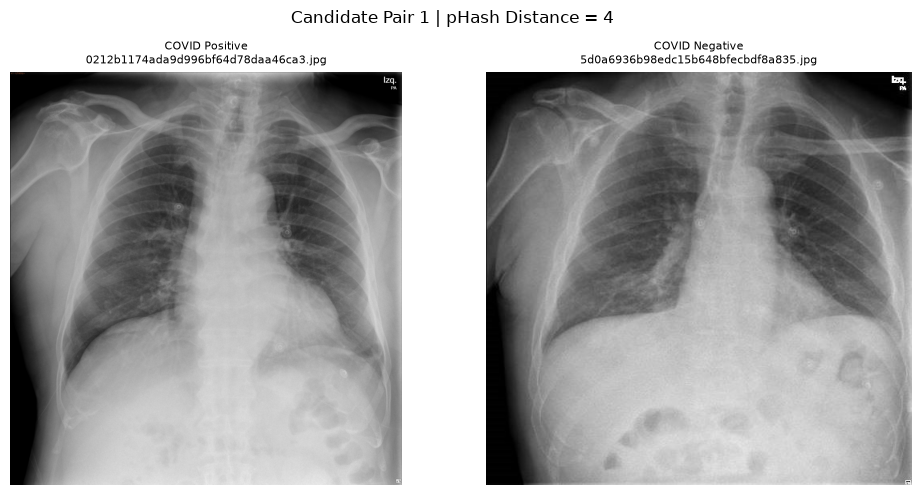

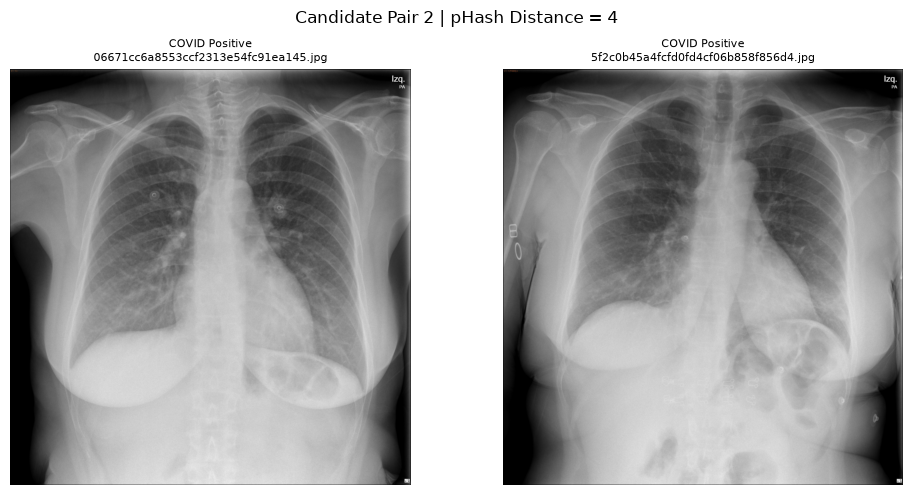

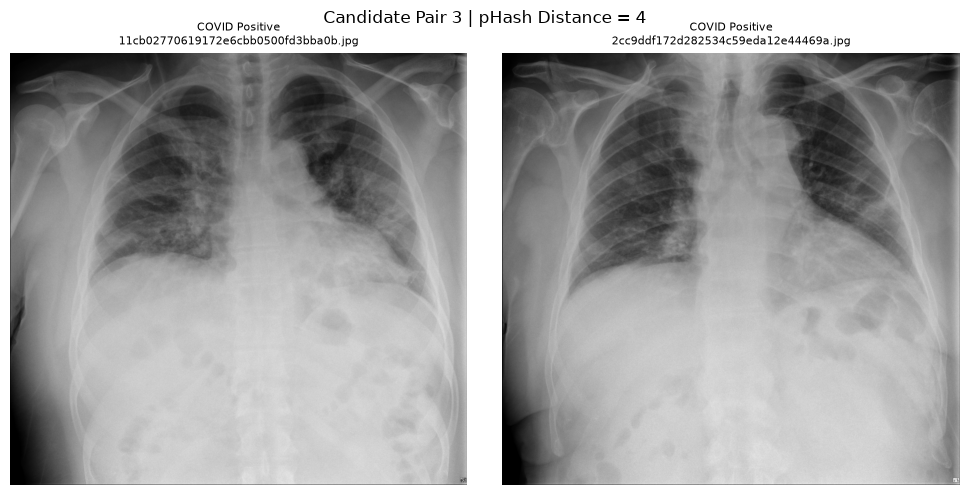

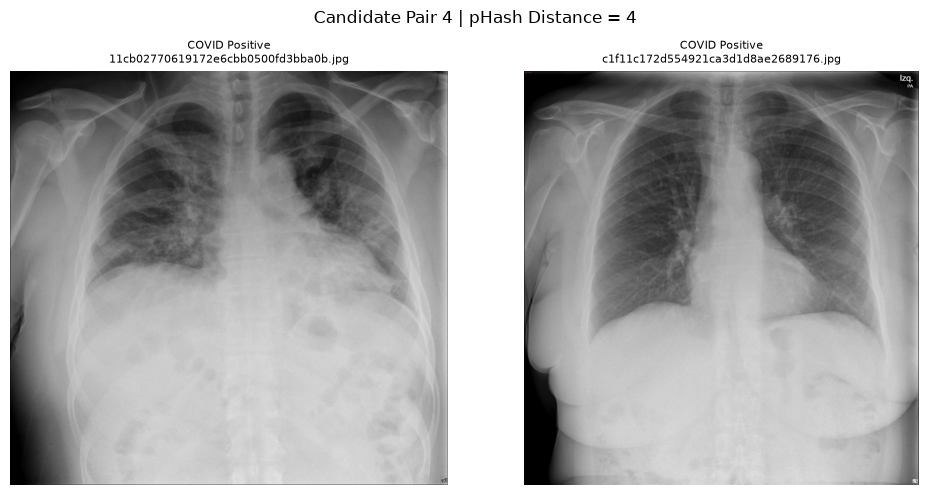

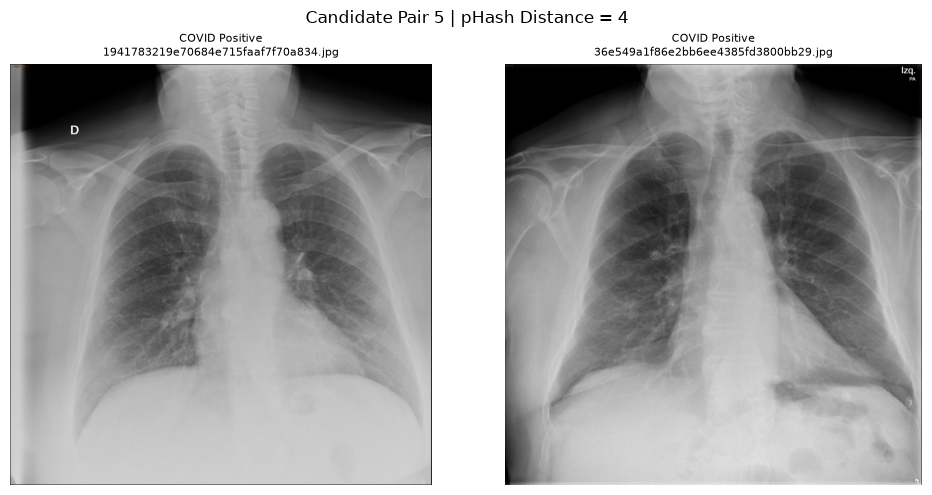

...

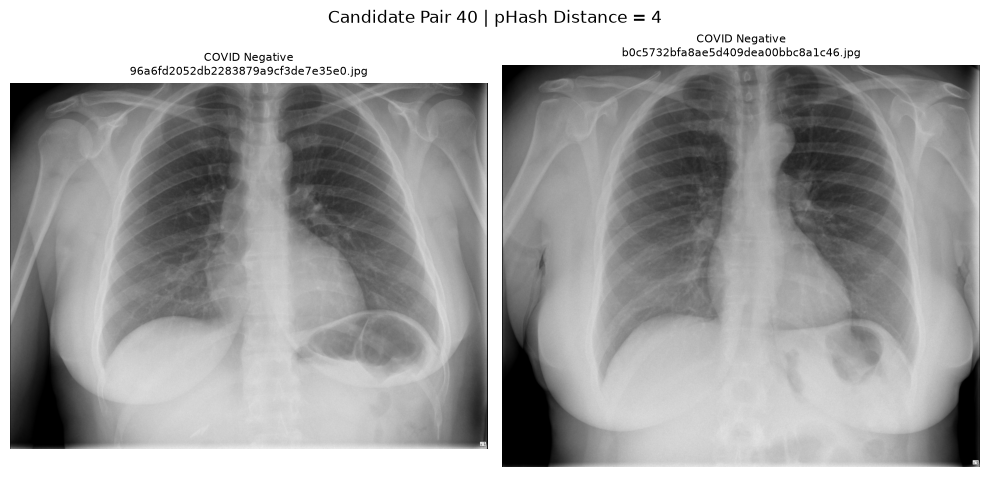

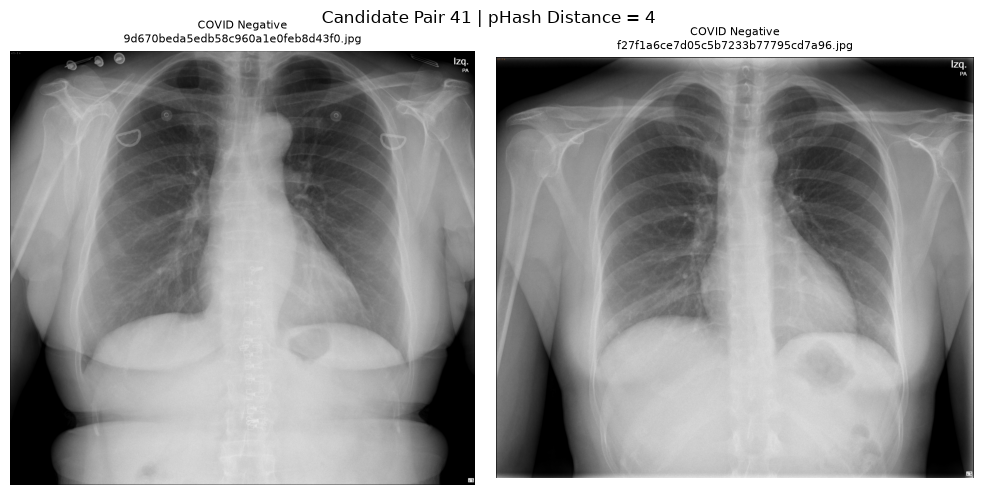

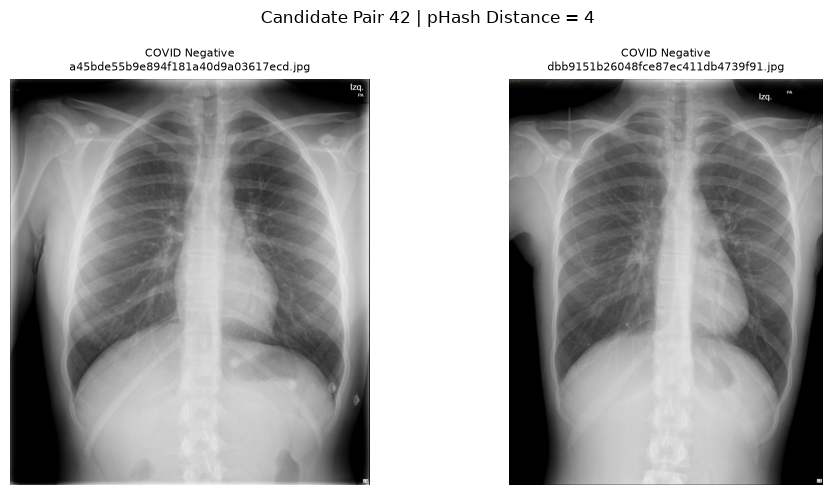

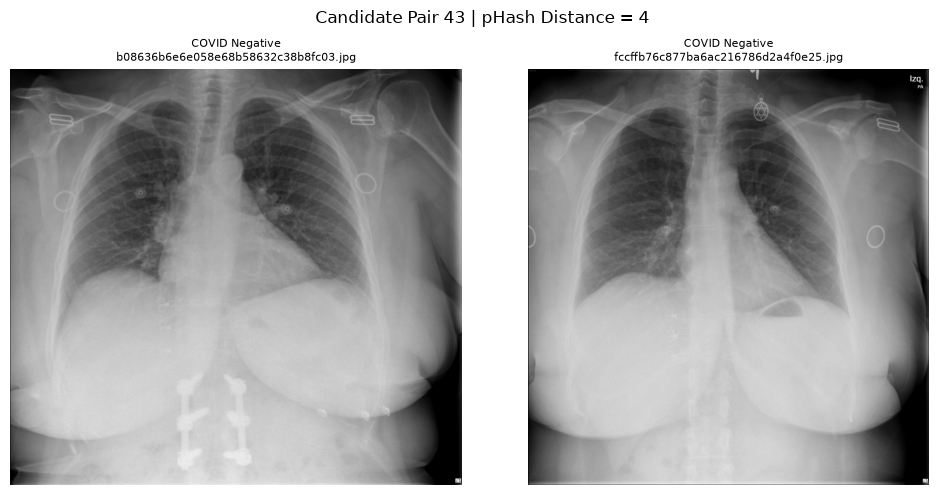

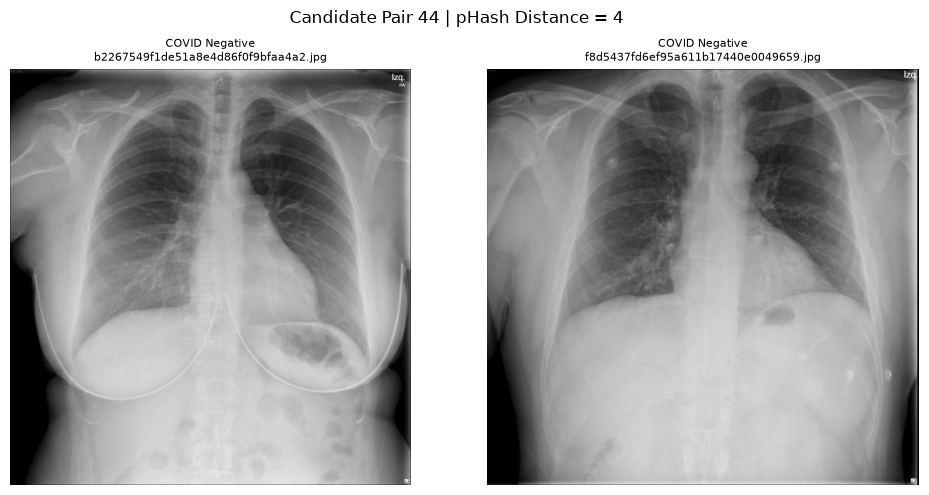

In [23]:
# Loop through every candidate near-duplicate pair.
# Each row in similar_df represents two images with pHash distance = 4.
for pair_number, (_, row) in enumerate(similar_df.iterrows(), start=1):

    # Get the class and filename of the first image.
    class_1 = row["class_1"]
    image_1 = row["image_1"]

    # Get the class and filename of the second image.
    class_2 = row["class_2"]
    image_2 = row["image_2"]

    # Build the full file path for the first image.
    # folders[class_1] retrieves the correct P or N folder.
    path_1 = os.path.join(
        folders[class_1],
        image_1
    )

    # Build the full file path for the second image.
    path_2 = os.path.join(
        folders[class_2],
        image_2
    )

    # Open both images using PIL.
    with Image.open(path_1) as img1, Image.open(path_2) as img2:

        # Create one row with two plots so both images
        # can be visually compared side by side.
        fig, axes = plt.subplots(
            1,
            2,
            figsize=(10, 5)
        )

        # Display the first image.
        axes[0].imshow(
            img1,
            cmap="gray"
        )

        # Show its class and filename above the image.
        axes[0].set_title(
            f"{class_1}\n{image_1}",
            fontsize=8
        )

        # Hide x-axis and y-axis values.
        axes[0].axis("off")


        # Display the second image.
        axes[1].imshow(
            img2,
            cmap="gray"
        )

        # Show its class and filename above the image.
        axes[1].set_title(
            f"{class_2}\n{image_2}",
            fontsize=8
        )

        # Hide x-axis and y-axis values.
        axes[1].axis("off")


        # Add an overall title showing the pair number
        # and the calculated pHash distance.
        fig.suptitle(
            f"Candidate Pair {pair_number} | pHash Distance = {row['distance']}",
            fontsize=12
        )

        # Adjust spacing between plots and titles.
        plt.tight_layout()

        # Display the current image pair.
        plt.show()

from visual inspection, they are all different images

STEP: SHARPNESS/BLUR ANALYSIS

In [24]:
# Import OpenCV, which provides image-processing functions
import cv2


# Create an empty list to store sharpness measurements
# for every image in the dataset
sharpness_data = []


# Loop through each class and its corresponding folder
for label, folder in folders.items():

    # Loop through every file inside the current folder
    for filename in os.listdir(folder):

        # Skip any file that is not a JPG image
        # This ignores files such as desktop.ini
        if not filename.lower().endswith(".jpg"):
            continue

        # Combine the folder path and filename
        # to create the full path to the image
        path = os.path.join(folder, filename)

        # Read the image directly as grayscale
        # cv2.IMREAD_GRAYSCALE converts RGB images to one channel
        img = cv2.imread(
            path,
            cv2.IMREAD_GRAYSCALE
        )

        # Apply the Laplacian operator to detect edges
        # CV_64F allows positive and negative edge values
        laplacian = cv2.Laplacian(
            img,
            cv2.CV_64F
        )

        # Calculate the variance of the Laplacian values
        # Higher variance usually means more visible edges / sharper image
        # Lower variance usually means fewer edges / blurrier image
        sharpness_score = laplacian.var()

        # Store the class, filename and calculated sharpness score
        sharpness_data.append({
            "class": label,
            "filename": filename,
            "sharpness": sharpness_score
        })


# Convert the collected measurements into a Pandas DataFrame
# Each row represents one X-ray image
sharpness_df = pd.DataFrame(sharpness_data)


# Display the first 5 rows to confirm the calculation worked
sharpness_df.head()

,class,filename,sharpness
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,376.783972
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,446.946197
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,312.227277
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,319.545754
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,190.338320


SUMMARIZE SHARPNESS BY CLASS using Laplacian variance

In [25]:
# Group the sharpness DataFrame by the "class" column.
# This separates the 426 COVID Positive images
# from the 426 COVID Negative images.
sharpness_summary = (
    sharpness_df
    .groupby("class")["sharpness"]

    # Calculate descriptive statistics for the sharpness scores
    # separately for each class.
    .agg([
        "count",    # Number of images in the class
        "mean",     # Average sharpness score
        "median",   # Middle sharpness score
        "std",      # How much sharpness varies between images
        "min",      # Lowest sharpness score (potentially blurriest image)
        "max"       # Highest sharpness score (potentially sharpest image)
    ])
)


# Display the summary table so the two classes
# can be compared side by side.
display(sharpness_summary)

,count,mean,median,std,min,max
class,,,,,,
COVID Negative,426,237.286830,202.382788,122.986252,50.028046,977.250170
COVID Positive,426,224.034112,193.328059,113.481941,8.323338,661.808614


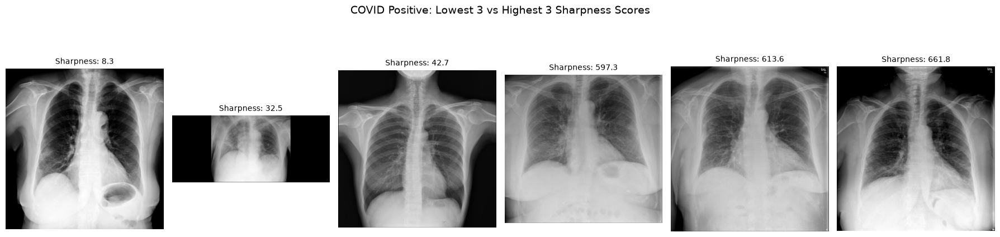

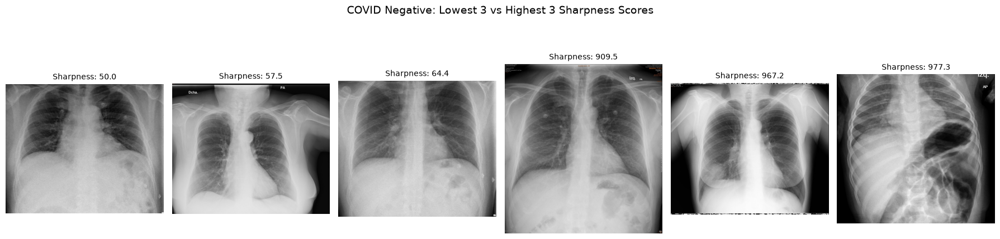

In [26]:
# Get the two unique class labels:
# "COVID Positive" and "COVID Negative".
classes = sharpness_df["class"].unique()


# Loop through each class separately so that Positive
# and Negative images are inspected independently.
for label in classes:

    # Select only rows belonging to the current class.
    class_data = sharpness_df[
        sharpness_df["class"] == label
    ]


    # Sort the current class from lowest sharpness score
    # to highest sharpness score.
    class_data = class_data.sort_values(
        "sharpness"
    )


    # Select the first 3 rows after sorting.
    # These are the 3 images with the LOWEST
    # Laplacian variance / sharpness scores.
    lowest = class_data.head(3)


    # Select the last 3 rows after sorting.
    # These are the 3 images with the HIGHEST
    # Laplacian variance / sharpness scores.
    highest = class_data.tail(3)


    # Combine the 3 lowest and 3 highest images
    # into one DataFrame containing 6 images.
    selected = pd.concat([
        lowest,
        highest
    ])


    # Create one figure containing 6 image positions.
    # The first 3 will be the lowest-scoring images,
    # and the last 3 will be the highest-scoring images.
    fig, axes = plt.subplots(
        1,
        6,
        figsize=(18, 5)
    )


    # Loop through the 6 selected image records.
    # ax represents the plot position.
    # row contains the filename and sharpness score.
    for ax, (_, row) in zip(
        axes,
        selected.iterrows()
    ):

        # Get the filename of the current image.
        filename = row["filename"]


        # Use the class label to retrieve the correct
        # Positive or Negative folder, then add the filename
        # to construct the complete image path.
        image_path = os.path.join(
            folders[label],
            filename
        )


        # Open the X-ray using PIL.
        with Image.open(image_path) as img:

            # Display the X-ray in the current subplot.
            ax.imshow(
                img,
                cmap="gray"
            )


        # Display the calculated sharpness score above
        # the image, rounded to one decimal place.
        ax.set_title(
            f"Sharpness: {row['sharpness']:.1f}",
            fontsize=10
        )


        # Remove the x-axis and y-axis because pixel
        # coordinates are unnecessary for this inspection.
        ax.axis("off")


    # Add a title identifying which class is being displayed.
    fig.suptitle(
        f"{label}: Lowest 3 vs Highest 3 Sharpness Scores",
        fontsize=14
    )


    # Adjust spacing between the images and titles.
    plt.tight_layout()


    # Display the completed figure for the current class.
    plt.show()

Sharpness: COVID-negative and positive images had similar median Laplacian-variance scores (202.38 vs 193.33). Extreme scores were observed, but manual inspection showed that Laplacian variance was strongly affected by image framing, anatomical coverage, borders and image composition rather than blur alone. Therefore, sharpness score should not be used as a standalone criterion for excluding images.

Image framing/coverage outliers: A small number of images show substantially different cropping or anatomical coverage compared with the majority of frontal chest radiographs. These should be investigated as potential preprocessing/outlier concerns.

BLACK AND WHITE PIXEL PROPORTIONS

In [27]:
# Create an empty list to store the dark/bright pixel statistics
# calculated for every X-ray image.
exposure_data = []


# Loop through each class and its corresponding folder.
# label = "COVID Positive" or "COVID Negative".
# folder = path to the P or N folder.
for label, folder in folders.items():

    # Loop through every file inside the current class folder.
    for filename in os.listdir(folder):

        # Only process JPG images.
        # This skips non-image files such as desktop.ini.
        if not filename.lower().endswith(".jpg"):
            continue

        # Combine the folder path and filename to create
        # the complete path to the current image.
        path = os.path.join(folder, filename)

        # Open the current X-ray using PIL.
        with Image.open(path) as img:

            # Convert the image to grayscale.
            # This makes RGB and L images directly comparable.
            gray_img = img.convert("L")

            # Convert the grayscale image into a NumPy array.
            # Each pixel is represented by a value from 0 to 255.
            pixel_array = np.array(gray_img)

            # Count the total number of pixels in the image.
            # .size returns the number of elements in the NumPy array.
            total_pixels = pixel_array.size

            # Count pixels with intensity <= 10.
            # These represent extremely dark / almost-black pixels.
            dark_pixels = np.sum(
                pixel_array <= 10
            )

            # Count pixels with intensity >= 245.
            # These represent extremely bright / almost-white pixels.
            bright_pixels = np.sum(
                pixel_array >= 245
            )

            # Calculate what percentage of the entire image
            # consists of extremely dark pixels.
            dark_percentage = (
                dark_pixels / total_pixels
            ) * 100

            # Calculate what percentage of the entire image
            # consists of extremely bright pixels.
            bright_percentage = (
                bright_pixels / total_pixels
            ) * 100

            # Store the results for the current image.
            exposure_data.append({

                # Store the image's class.
                "class": label,

                # Store the filename so unusual images
                # can be located and inspected later.
                "filename": filename,

                # Percentage of almost-black pixels.
                "dark_pixel_pct": dark_percentage,

                # Percentage of almost-white pixels.
                "bright_pixel_pct": bright_percentage
            })


# Convert all collected results into a Pandas DataFrame.
# Each row now represents one X-ray image.
exposure_df = pd.DataFrame(exposure_data)


# Display the first five rows to make sure
# the calculations were performed correctly.
exposure_df.head()

,class,filename,dark_pixel_pct,bright_pixel_pct
0,COVID Positive,0021a3ef8340e3c2a599843997e94c76.jpg,2.138233,0.011407
1,COVID Positive,00960b9bd138047f3b868404aac7e531.jpg,2.410519,0.010452
2,COVID Positive,00b05aa3cb325265b9ded3f1a9f704c8.jpg,12.181268,0.011951
3,COVID Positive,00f9707e0de334db70a7924a9de98368.jpg,0.945358,0.011836
4,COVID Positive,0187b7c65ef69abd633c9bad6675dabf.jpg,3.327989,0.000000


In [28]:
# Group the exposure measurements by class.
# This separates COVID Positive images from COVID Negative images.
exposure_summary = (
    exposure_df
    .groupby("class")[["dark_pixel_pct", "bright_pixel_pct"]]

    # Calculate descriptive statistics for both measurements.
    # mean   = average percentage across all images in the class.
    # median = middle value and is less affected by extreme outliers.
    # std    = how much the percentages vary between images.
    # min    = smallest percentage found in the class.
    # max    = largest percentage found in the class.
    .agg([
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)


# Display the summary table so we can compare
# COVID Positive and COVID Negative images.
display(exposure_summary)

dark_pixel_pct                                      \
                         mean    median       std  min        max   
class                                                               
COVID Negative       6.592215  5.428522  6.977466  0.0  61.538364   
COVID Positive       5.129068  4.191607  4.753371  0.0  50.876549   

               bright_pixel_pct                                      
                           mean    median       std  min        max  
class                                                                
COVID Negative         0.108236  0.030674  0.727472  0.0  12.164254  
COVID Positive         0.338938  0.020301  2.273070  0.0  33.547260

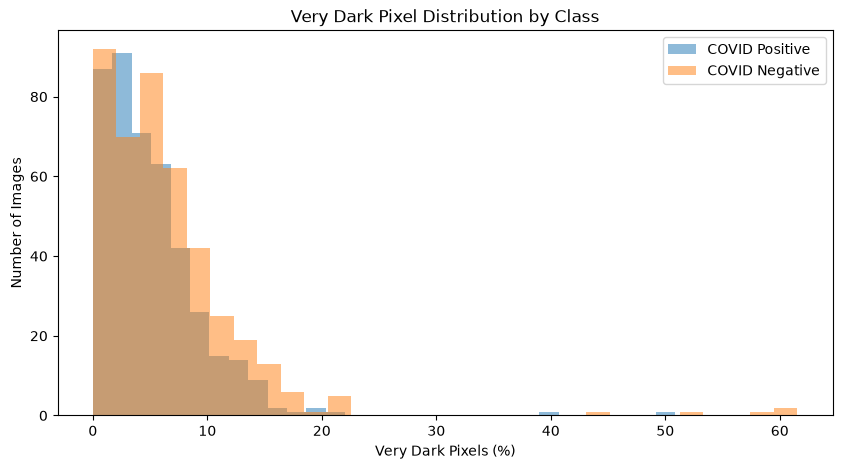

In [29]:
# Create a new figure for the dark-pixel distribution.
plt.figure(figsize=(10, 5))


# Loop through each class:
# COVID Positive and COVID Negative.
for label in exposure_df["class"].unique():

    # Select only the rows belonging to the current class.
    # Then retrieve the percentage of very dark pixels
    # (pixels with intensity <= 10) for those images.
    dark_values = exposure_df[
        exposure_df["class"] == label
    ]["dark_pixel_pct"]

    # Plot a histogram of the dark-pixel percentages.
    # bins=30 divides the range into 30 intervals.
    # alpha=0.5 makes the bars partially transparent so
    # the Positive and Negative distributions can be compared.
    # label=label identifies the class in the legend.
    plt.hist(
        dark_values,
        bins=30,
        alpha=0.5,
        label=label
    )


# Label the horizontal axis.
# This represents the percentage of each image
# consisting of pixels with intensity <= 10.
plt.xlabel("Very Dark Pixels (%)")


# Label the vertical axis.
# This shows how many X-rays fall into each range.
plt.ylabel("Number of Images")


# Add a descriptive title to the graph.
plt.title("Very Dark Pixel Distribution by Class")


# Display the class labels.
plt.legend()


# Display the completed histogram.
plt.show()

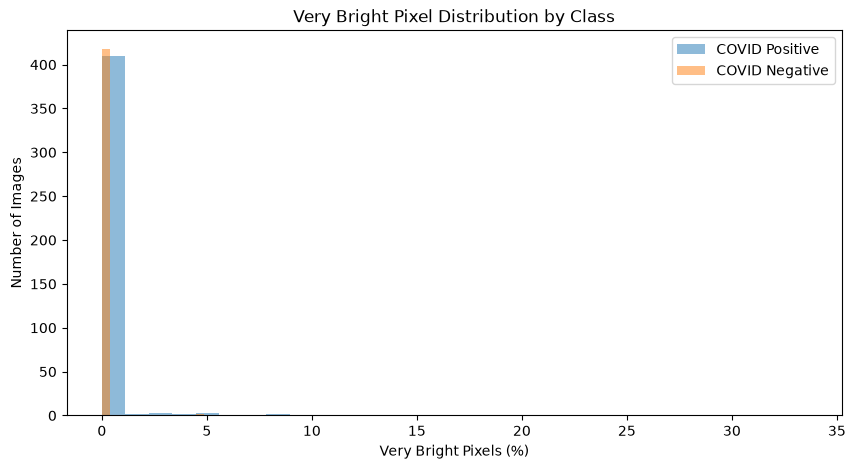

In [30]:
# Create a new figure for the bright-pixel distribution.
plt.figure(figsize=(10, 5))


# Loop through COVID Positive and COVID Negative separately.
for label in exposure_df["class"].unique():

    # Select only images belonging to the current class.
    # Then retrieve the percentage of very bright pixels
    # (pixels with intensity >= 245).
    bright_values = exposure_df[
        exposure_df["class"] == label
    ]["bright_pixel_pct"]

    # Plot the distribution of very bright pixel percentages.
    # Transparency allows the two classes to overlap visibly.
    plt.hist(
        bright_values,
        bins=30,
        alpha=0.5,
        label=label
    )


# Label the horizontal axis.
# This represents the percentage of each image
# consisting of pixels with intensity >= 245.
plt.xlabel("Very Bright Pixels (%)")


# Label the vertical axis with the number of images.
plt.ylabel("Number of Images")


# Add a descriptive title.
plt.title("Very Bright Pixel Distribution by Class")


# Display the class labels.
plt.legend()


# Display the completed histogram.
plt.show()

Extreme pixel / framing analysis: Most COVID-positive and COVID-negative images showed similar proportions of very dark and very bright pixels. However, a small number of substantial outliers were observed, with dark-pixel proportions reaching 50.88% (positive) and 61.54% (negative), and bright-pixel proportions reaching 33.55% and 12.16%, respectively. These may represent unusual framing, borders, exposure, or acquisition characteristics and warrant visual inspection.

IDENTIFY EXTREME IMAGES


In [31]:
# Sort all images from the HIGHEST dark-pixel percentage
# to the lowest.
darkest_outliers = exposure_df.sort_values(
    "dark_pixel_pct",
    ascending=False
)


# Select only the top 10 images with the largest
# proportion of extremely dark pixels.
darkest_outliers = darkest_outliers.head(10)


# Sort all images from the HIGHEST bright-pixel percentage
# to the lowest.
brightest_outliers = exposure_df.sort_values(
    "bright_pixel_pct",
    ascending=False
)


# Select only the top 10 images with the largest
# proportion of extremely bright pixels.
brightest_outliers = brightest_outliers.head(10)


# Display the top dark-pixel outliers.
print("Top 10 images by very dark pixel percentage:")
display(
    darkest_outliers[
        ["class", "filename", "dark_pixel_pct", "bright_pixel_pct"]
    ]
)


# Display the top bright-pixel outliers.
print("Top 10 images by very bright pixel percentage:")
display(
    brightest_outliers[
        ["class", "filename", "dark_pixel_pct", "bright_pixel_pct"]
    ]
)

Top 10 images by very dark pixel percentage:


,class,filename,dark_pixel_pct,bright_pixel_pct
731,COVID Negative,b855d668c681bb95f20871d9ab52b7bb.jpg,61.538364,0.013873
785,COVID Negative,db943dfaad8e1d5c2ca24a4fda8b9cfb.jpg,59.667521,0.014479
621,COVID Negative,7e826b17350c62f402a193f2c8e78146.jpg,57.815892,0.016442
429,COVID Negative,03465f96a67979c916a3646ef55157a4.jpg,51.613732,0.018290
43,COVID Positive,1a77e4bd2fe33f616179273a53ff8ade.jpg,50.876549,0.000000
571,COVID Negative,5b5399dfa6fe8375f1750091e10504e2.jpg,44.770793,0.021913
234,COVID Positive,8422d0b0c4f831040e6bc62f99701b0c.jpg,40.664959,0.028952
675,COVID Negative,9e25ce3b77e6dc54189e47016855fded.jpg,22.289336,0.029634
125,COVID Positive,4414e42e0c548ee395efcc4d5f56f6c5.jpg,21.915794,0.006991
655,COVID Negative,93b0501557b2d89730ec9ea6a0d2daa7.jpg,21.487089,0.030546


Top 10 images by very bright pixel percentage:


,class,filename,dark_pixel_pct,bright_pixel_pct
183,COVID Positive,661b5807eac8deaf3adcb908d34ecf44.jpg,2.938801,33.547260
104,COVID Positive,3a1c7e55986c2b2032a447ca0ae3f9cf.jpg,9.654471,21.406277
273,COVID Positive,9dab1fc8d9573b336590123a3e1de832.jpg,6.348334,17.027831
685,COVID Negative,a4760631ce105db394905f8075e45a5e.jpg,7.594372,12.164254
93,COVID Positive,34efdc647ec140749e16ba6b5f8ee10d.jpg,1.618205,9.431158
281,COVID Positive,a20e84e08ae6a2c915bbe665e35a4db8.jpg,7.918384,8.512771
86,COVID Positive,32516a638ec1793052ebb9ee55872c86.jpg,4.993445,8.053604
211,COVID Positive,780a90391a4e821e1f50b0ba01c369ba.jpg,12.627385,5.493630
82,COVID Positive,303eae81561c48dd64a15e03f8b66ac7.jpg,10.881008,5.369467
834,COVID Negative,f7a64ff16059c8b6f68a387dcd193920.jpg,12.807330,5.311614


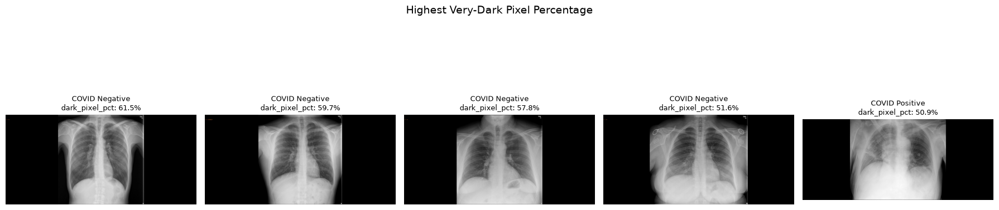

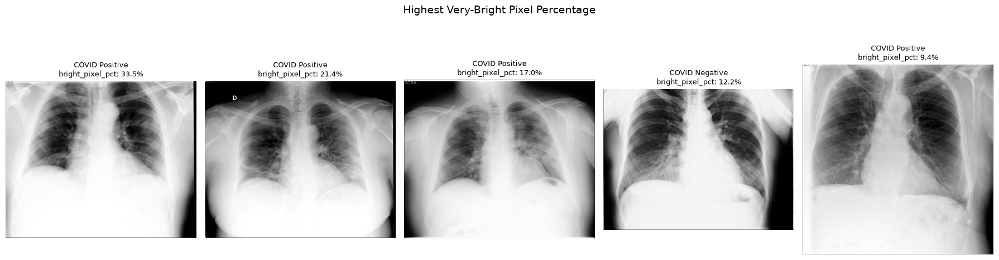

In [32]:
# Select the 5 images with the highest percentage
# of extremely dark pixels (pixel intensity <= 10).
top_dark = exposure_df.nlargest(
    5,
    "dark_pixel_pct"
)


# Select the 5 images with the highest percentage
# of extremely bright pixels (pixel intensity >= 245).
top_bright = exposure_df.nlargest(
    5,
    "bright_pixel_pct"
)


# Create a list containing the two groups we want to inspect.
# Each item contains:
# 1. A title for the figure
# 2. The DataFrame containing the selected images
# 3. The measurement that should be displayed above each image
outlier_groups = [
    (
        "Highest Very-Dark Pixel Percentage",
        top_dark,
        "dark_pixel_pct"
    ),
    (
        "Highest Very-Bright Pixel Percentage",
        top_bright,
        "bright_pixel_pct"
    )
]


# Loop through the two outlier groups:
# first the dark-pixel outliers, then the bright-pixel outliers.
for title, selected_images, metric in outlier_groups:

    # Create a figure containing 5 plots in one row.
    # Each plot will display one of the selected outlier images.
    fig, axes = plt.subplots(
        1,
        5,
        figsize=(18, 5)
    )


    # Loop through the 5 selected image records.
    # ax represents the subplot where the image will be displayed.
    # row contains the class, filename and exposure measurements.
    for ax, (_, row) in zip(
        axes,
        selected_images.iterrows()
    ):

        # Retrieve the class of the current image.
        # This tells us whether we need the P or N folder.
        label = row["class"]


        # Retrieve the filename of the current image.
        filename = row["filename"]


        # Use the class label to retrieve the correct folder
        # from our existing "folders" dictionary.
        #
        # Then combine that folder path with the filename
        # to obtain the full path to the image.
        image_path = os.path.join(
            folders[label],
            filename
        )


        # Open the current X-ray image using PIL.
        # "with" automatically closes the image after use.
        with Image.open(image_path) as img:

            # Display the X-ray in the current subplot.
            ax.imshow(
                img,
                cmap="gray"
            )


        # Display three pieces of information above each image:
        #
        # 1. COVID Positive / COVID Negative
        # 2. Which metric is being examined
        # 3. The percentage for that image
        #
        # :.1f rounds the percentage to one decimal place.
        ax.set_title(
            f"{label}\n"
            f"{metric}: {row[metric]:.1f}%",
            fontsize=9
        )


        # Remove the x-axis and y-axis because the pixel
        # coordinates are not useful for visual inspection.
        ax.axis("off")


    # Add a main title above all 5 images explaining
    # which type of outlier is currently being displayed.
    fig.suptitle(
        title,
        fontsize=14
    )


    # Automatically adjust the spacing between images
    # while leaving room at the top for the main title.
    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )


    # Display the completed figure.
    plt.show()

Exposure/framing outliers: Extreme dark/bright pixel percentages were primarily associated with differences in image framing, black margins and acquisition/exposure rather than obviously corrupted images. No images were excluded at this stage. Consistent cropping/ROI extraction and resizing should be considered during final preprocessing.

In [33]:
# Make sure aspect ratio exists in image_df.
# Aspect ratio = image width divided by image height.
image_df["aspect_ratio"] = (
    image_df["width"]
    /
    image_df["height"]
)


# Calculate overall dataset statistics for width, height,
# and aspect ratio using all 852 images.
overall_dimension_stats = (
    image_df[
        ["width", "height", "aspect_ratio"]
    ]
    .agg([
        "mean",   # Average value
        "std",    # Standard deviation / spread
        "min",    # Smallest value
        "max"     # Largest value
    ])
)


# Select only COVID Positive images.
covid_positive_df = image_df[
    image_df["class"] == "COVID Positive"
]


# Calculate width, height and aspect-ratio averages
# for COVID Positive images only.
covid_positive_dimension_stats = (
    covid_positive_df[
        ["width", "height", "aspect_ratio"]
    ]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
)


# Select only COVID Negative images.
covid_negative_df = image_df[
    image_df["class"] == "COVID Negative"
]


# Calculate width, height and aspect-ratio statistics
# for COVID Negative images only.
covid_negative_dimension_stats = (
    covid_negative_df[
        ["width", "height", "aspect_ratio"]
    ]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
)


# Display the overall dataset statistics.
print("Overall dimension statistics:")
display(overall_dimension_stats)


# Display COVID Positive statistics.
print("COVID Positive dimension statistics:")
display(covid_positive_dimension_stats)


# Display COVID Negative statistics.
print("COVID Negative dimension statistics:")
display(covid_negative_dimension_stats)

Overall dimension statistics:


,width,height,aspect_ratio
mean,2591.866197,2461.913146,1.063615
std,385.901269,411.737572,0.142476
min,492.000000,464.000000,0.773876
max,3840.000000,3056.000000,2.364532


COVID Positive dimension statistics:


,width,height,aspect_ratio
mean,2570.394366,2429.307512,1.066791
std,348.439904,372.099515,0.123673
min,514.000000,466.000000,0.792079
max,3840.000000,3000.000000,2.364532


COVID Negative dimension statistics:


,width,height,aspect_ratio
mean,2613.338028,2494.518779,1.060439
std,419.351122,445.943089,0.159159
min,492.000000,464.000000,0.773876
max,3840.000000,3056.000000,2.128603


In [34]:
# Select only COVID Negative images from the image metadata DataFrame.
negative_images = image_df[
    image_df["class"] == "COVID Negative"
]


# Select only COVID Negative images from the brightness/contrast DataFrame.
negative_intensity = intensity_df[
    intensity_df["class"] == "COVID Negative"
]


# Calculate the number of COVID Negative images.
negative_count = len(negative_images)


# Calculate the average width of COVID Negative images.
negative_width_mean = negative_images["width"].mean()


# Calculate the average height of COVID Negative images.
negative_height_mean = negative_images["height"].mean()


# Calculate the average aspect ratio of COVID Negative images.
negative_aspect_ratio_mean = negative_images["aspect_ratio"].mean()


# Calculate the average brightness (mean pixel intensity)
# across all COVID Negative images.
negative_brightness_mean = (
    negative_intensity["mean_intensity"].mean()
)


# Calculate the standard deviation of image brightness.
# This measures how much average brightness varies
# between COVID Negative images.
negative_brightness_std = (
    negative_intensity["mean_intensity"].std()
)


# Calculate the average contrast of COVID Negative images.
# std_intensity is the within-image pixel standard deviation
# that we previously used as our contrast measurement.
negative_contrast_mean = (
    negative_intensity["std_intensity"].mean()
)


# Calculate how much the contrast measurement varies
# between COVID Negative images.
negative_contrast_std = (
    negative_intensity["std_intensity"].std()
)


# Print all calculated values so we can verify them
# before adding them to the CSV.
print("COVID Negative count:", negative_count)

print(
    "COVID Negative width mean:",
    negative_width_mean
)

print(
    "COVID Negative height mean:",
    negative_height_mean
)

print(
    "COVID Negative aspect ratio mean:",
    negative_aspect_ratio_mean
)

print(
    "COVID Negative brightness mean:",
    negative_brightness_mean
)

print(
    "COVID Negative brightness std:",
    negative_brightness_std
)

print(
    "COVID Negative contrast mean:",
    negative_contrast_mean
)

print(
    "COVID Negative contrast std:",
    negative_contrast_std
)

COVID Negative count: 426
COVID Negative width mean: 2613.3380281690143
COVID Negative height mean: 2494.518779342723
COVID Negative aspect ratio mean: 1.0604391452213402
COVID Negative brightness mean: 132.83114756845046
COVID Negative brightness std: 12.944357168130207
COVID Negative contrast mean: 59.12526987918427
COVID Negative contrast std: 6.932093828687496


In [35]:
# Store the path to the CSV containing your dataset EDA summaries.
# Change this to the actual location of your CSV file.
summary_csv_path = r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\dataset_summary.csv"


# Read the existing summary CSV into a Pandas DataFrame.
summary_df = pd.read_csv(summary_csv_path)


# Create a list containing the new COVID Negative columns
# that we want all datasets to have.
negative_columns = [
    "COVID_Negative_Count",
    "COVID_Negative_Width_Mean",
    "COVID_Negative_Height_Mean",
    "COVID_Negative_Aspect_Ratio_Mean",
    "COVID_Negative_Brightness_Mean",
    "COVID_Negative_Brightness_Std",
    "COVID_Negative_Contrast_Mean",
    "COVID_Negative_Contrast_Std"
]


# Loop through each new column name.
for column in negative_columns:

    # Check whether the column already exists in the CSV.
    # This prevents accidentally recreating an existing column.
    if column not in summary_df.columns:

        # Create the new column.
        # pd.NA means the value is currently missing/not available.
        summary_df[column] = pd.NA


# Display the column names so we can verify that
# the new COVID Negative columns were successfully added.
print(summary_df.columns.tolist())


# Display the current summary table.
# Dataset 1 should now contain NA in the newly created columns
# until we populate its Negative statistics.
display(summary_df)

['ID', 'Name', 'Total_Images', 'COVID_Count', 'Pneumonia_Count', 'Normal_Count', 'Width_Mean', 'Width_Std', 'Width_Min', 'Width_Max', 'Height_Mean', 'Height_Std', 'Height_Min', 'Height_Max', 'Aspect_Ratio_Mean', 'Aspect_Ratio_Std', 'Main_Resolution', 'Grayscale_Count', 'RGB_Count', 'Other_Mode_Count', 'Brightness_Mean', 'Brightness_Std', 'Contrast_Mean', 'Contrast_Std', 'Min_Intensity_Mean', 'Max_Intensity_Mean', 'Exact_Duplicate_Groups', 'Exact_Duplicate_Images', 'COVID_Width_Mean', 'COVID_Height_Mean', 'COVID_Aspect_Ratio_Mean', 'COVID_Brightness_Mean', 'COVID_Brightness_Std', 'COVID_Contrast_Mean', 'COVID_Contrast_Std', 'Pneumonia_Width_Mean', 'Pneumonia_Height_Mean', 'Pneumonia_Aspect_Ratio_Mean', 'Pneumonia_Brightness_Mean', 'Pneumonia_Brightness_Std', 'Pneumonia_Contrast_Mean', 'Pneumonia_Contrast_Std', 'Normal_Width_Mean', 'Normal_Height_Mean', 'Normal_Aspect_Ratio_Mean', 'Normal_Brightness_Mean', 'Normal_Brightness_Std', 'Normal_Contrast_Mean', 'Normal_Contrast_Std', 'COVID_Neg

,ID,Name,Total_Images,COVID_Count,Pneumonia_Count,Normal_Count,Width_Mean,Width_Std,Width_Min,Width_Max,...,Normal_Contrast_Mean,Normal_Contrast_Std,COVID_Negative_Count,COVID_Negative_Width_Mean,COVID_Negative_Height_Mean,COVID_Negative_Aspect_Ratio_Mean,COVID_Negative_Brightness_Mean,COVID_Negative_Brightness_Std,COVID_Negative_Contrast_Mean,COVID_Negative_Contrast_Std
0,1,COVID-19 Chest X-ray Image Database,3886,1200,1345,1341,812.77,334.0,187,1275,...,61.38,5.6,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [36]:
# Create a dictionary containing every column that already exists
# in the summary CSV.
#
# Each column initially receives pd.NA.
# This prevents us from accidentally forgetting a column or
# creating a row whose structure differs from Dataset 1.
covidgr_row = {
    column: pd.NA
    for column in summary_df.columns
}


# ---------------------------------------------------------
# BASIC DATASET INFORMATION
# ---------------------------------------------------------

# Dataset ID.
covidgr_row["ID"] = 2

# Dataset name.
covidgr_row["Name"] = "COVIDGR 1.0"

# Total number of readable X-ray images.
covidgr_row["Total_Images"] = 852

# Number of COVID Positive images.
covidgr_row["COVID_Count"] = 426

# COVIDGR does not contain a separate pneumonia class.
covidgr_row["Pneumonia_Count"] = 0

# COVID Negative does NOT necessarily mean clinically normal.
# Therefore we should not incorrectly count the 426 negatives
# as "Normal".
covidgr_row["Normal_Count"] = 0


# ---------------------------------------------------------
# OVERALL IMAGE DIMENSIONS
# ---------------------------------------------------------

# Average width across all 852 images.
covidgr_row["Width_Mean"] = image_df["width"].mean()

# Standard deviation of image widths.
covidgr_row["Width_Std"] = image_df["width"].std()

# Smallest image width.
covidgr_row["Width_Min"] = image_df["width"].min()

# Largest image width.
covidgr_row["Width_Max"] = image_df["width"].max()

# Average height across all images.
covidgr_row["Height_Mean"] = image_df["height"].mean()

# Standard deviation of image heights.
covidgr_row["Height_Std"] = image_df["height"].std()

# Smallest image height.
covidgr_row["Height_Min"] = image_df["height"].min()

# Largest image height.
covidgr_row["Height_Max"] = image_df["height"].max()

# Average width-to-height ratio.
covidgr_row["Aspect_Ratio_Mean"] = image_df["aspect_ratio"].mean()

# Standard deviation of width-to-height ratio.
covidgr_row["Aspect_Ratio_Std"] = image_df["aspect_ratio"].std()


# ---------------------------------------------------------
# COVID POSITIVE STATISTICS
# ---------------------------------------------------------

# Store the number of COVID Positive images.
# COVID_Count above already contains this, so no additional
# class-count column is required unless your CSV has one.

# Average width of COVID Positive images.
covidgr_row["COVID_Width_Mean"] = (
    covid_positive_df["width"].mean()
)

# Average height of COVID Positive images.
covidgr_row["COVID_Height_Mean"] = (
    covid_positive_df["height"].mean()
)

# Average aspect ratio of COVID Positive images.
covidgr_row["COVID_Aspect_Ratio_Mean"] = (
    covid_positive_df["aspect_ratio"].mean()
)

# Select brightness/contrast records belonging
# only to COVID Positive images.
positive_intensity = intensity_df[
    intensity_df["class"] == "COVID Positive"
]

# Average brightness of COVID Positive images.
covidgr_row["COVID_Brightness_Mean"] = (
    positive_intensity["mean_intensity"].mean()
)

# Variation in brightness between COVID Positive images.
covidgr_row["COVID_Brightness_Std"] = (
    positive_intensity["mean_intensity"].std()
)

# Average contrast of COVID Positive images.
covidgr_row["COVID_Contrast_Mean"] = (
    positive_intensity["std_intensity"].mean()
)

# Variation in contrast between COVID Positive images.
covidgr_row["COVID_Contrast_Std"] = (
    positive_intensity["std_intensity"].std()
)


# ---------------------------------------------------------
# COVID NEGATIVE STATISTICS
# ---------------------------------------------------------

# Number of COVID Negative images.
covidgr_row["COVID_Negative_Count"] = negative_count

# Average width of COVID Negative images.
covidgr_row["COVID_Negative_Width_Mean"] = (
    negative_width_mean
)

# Average height of COVID Negative images.
covidgr_row["COVID_Negative_Height_Mean"] = (
    negative_height_mean
)

# Average aspect ratio of COVID Negative images.
covidgr_row["COVID_Negative_Aspect_Ratio_Mean"] = (
    negative_aspect_ratio_mean
)

# Average brightness of COVID Negative images.
covidgr_row["COVID_Negative_Brightness_Mean"] = (
    negative_brightness_mean
)

# Variation in brightness between COVID Negative images.
covidgr_row["COVID_Negative_Brightness_Std"] = (
    negative_brightness_std
)

# Average contrast of COVID Negative images.
covidgr_row["COVID_Negative_Contrast_Mean"] = (
    negative_contrast_mean
)

# Variation in contrast between COVID Negative images.
covidgr_row["COVID_Negative_Contrast_Std"] = (
    negative_contrast_std
)


# ---------------------------------------------------------
# PREVIEW THE NEW ROW
# ---------------------------------------------------------

# Convert the dictionary into a one-row DataFrame.
# Using columns=summary_df.columns guarantees that the new
# row follows exactly the same column order as Dataset 1.
covidgr_row_df = pd.DataFrame(
    [covidgr_row],
    columns=summary_df.columns
)


# Display the row before writing anything to the CSV.
display(covidgr_row_df)

,ID,Name,Total_Images,COVID_Count,Pneumonia_Count,Normal_Count,Width_Mean,Width_Std,Width_Min,Width_Max,...,Normal_Contrast_Mean,Normal_Contrast_Std,COVID_Negative_Count,COVID_Negative_Width_Mean,COVID_Negative_Height_Mean,COVID_Negative_Aspect_Ratio_Mean,COVID_Negative_Brightness_Mean,COVID_Negative_Brightness_Std,COVID_Negative_Contrast_Mean,COVID_Negative_Contrast_Std
0,2,COVIDGR 1.0,852,426,0,0,2591.866197,385.901269,492,3840,...,<NA>,<NA>,426,2613.338028,2494.518779,1.060439,132.831148,12.944357,59.12527,6.932094


In [37]:
# Append the COVIDGR row underneath the existing Dataset 1 row.
#
# ignore_index=True creates a clean DataFrame index:
# 0 = Dataset 1
# 1 = Dataset 2
summary_df = pd.concat(
    [
        summary_df,
        covidgr_row_df
    ],
    ignore_index=True
)


# Save the updated DataFrame back to the same CSV file.
#
# index=False prevents Pandas from creating an unnecessary
# extra index column in the CSV.
summary_df.to_csv(
    summary_csv_path,
    index=False
)


# Display the updated summary table.
# You should now see:
# ID 1 = COVID-19 Chest X-ray Image Database
# ID 2 = COVIDGR 1.0
display(summary_df)


# Confirm that the file was successfully saved.
print(
    f"Updated dataset summary saved to:\n{summary_csv_path}"
)

,ID,Name,Total_Images,COVID_Count,Pneumonia_Count,Normal_Count,Width_Mean,Width_Std,Width_Min,Width_Max,...,Normal_Contrast_Mean,Normal_Contrast_Std,COVID_Negative_Count,COVID_Negative_Width_Mean,COVID_Negative_Height_Mean,COVID_Negative_Aspect_Ratio_Mean,COVID_Negative_Brightness_Mean,COVID_Negative_Brightness_Std,COVID_Negative_Contrast_Mean,COVID_Negative_Contrast_Std
0,1,COVID-19 Chest X-ray Image Database,3886,1200,1345,1341,812.770000,334.000000,187,1275,...,61.38,5.6,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,2,COVIDGR 1.0,852,426,0,0,2591.866197,385.901269,492,3840,...,<NA>,<NA>,426,2613.338028,2494.518779,1.060439,132.831148,12.944357,59.12527,6.932094


Updated dataset summary saved to:
C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\dataset_summary.csv


PREPROCESSING STARTS

In [1]:
#BUILD A CLEAN DF FIRST

import os
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image

base_path = Path(
    r"C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\COVIDGR 1.0"
)

folders = {
    "COVID": base_path / "COVIDGR_1.0" / "P",
    "Non-COVID": base_path / "COVIDGR_1.0" / "N"
}

records = []

for original_label, folder_path in folders.items():
    for filepath in folder_path.glob("*.jpg"):
        records.append({
            "filepath": str(filepath),
            "filename": filepath.name,
            "original_label": original_label,
            "covid_target": int(original_label == "COVID"),
            "source_dataset": "COVIDGR_1.0"
        })

dataset2_df = pd.DataFrame(records)

print("Total images:", len(dataset2_df))

print("\nOriginal class distribution:")
print(dataset2_df["original_label"].value_counts())

print("\nBinary target distribution:")
print(dataset2_df["covid_target"].value_counts().sort_index())

display(dataset2_df.head())

Total images: 852

Original class distribution:
original_label
COVID        426
Non-COVID    426
Name: count, dtype: int64

Binary target distribution:
covid_target
0    426
1    426
Name: count, dtype: int64


,filepath,filename,original_label,covid_target,source_dataset
0,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,0021a3ef8340e3c2a599843997e94c76.jpg,COVID,1,COVIDGR_1.0
1,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00960b9bd138047f3b868404aac7e531.jpg,COVID,1,COVIDGR_1.0
2,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00b05aa3cb325265b9ded3f1a9f704c8.jpg,COVID,1,COVIDGR_1.0
3,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00f9707e0de334db70a7924a9de98368.jpg,COVID,1,COVIDGR_1.0
4,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,0187b7c65ef69abd633c9bad6675dabf.jpg,COVID,1,COVIDGR_1.0


In [2]:
#STEP 2 VALIDATE FILES AND ADD IMAGE PROPERTIES
image_properties = []
invalid_images = []

for _, row in dataset2_df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            img.verify()

        # Reopen after verify() to read image properties
        with Image.open(row["filepath"]) as img:
            width, height = img.size

            image_properties.append({
                "filepath": row["filepath"],
                "mode": img.mode,
                "width": width,
                "height": height,
                "aspect_ratio": round(width / height, 4)
            })

    except Exception as e:
        invalid_images.append({
            "filepath": row["filepath"],
            "error": str(e)
        })

properties2_df = pd.DataFrame(image_properties)
invalid2_df = pd.DataFrame(invalid_images)

print("Unreadable/corrupted images:", len(invalid2_df))

print("\nImage modes:")
print(properties2_df["mode"].value_counts())

print("\nDimension summary:")
display(
    properties2_df[
        ["width", "height", "aspect_ratio"]
    ].describe()
)

Unreadable/corrupted images: 0

Image modes:
mode
RGB    571
L      281
Name: count, dtype: int64

Dimension summary:


,width,height,aspect_ratio
count,852.000000,852.000000,852.000000
mean,2591.866197,2461.913146,1.063616
std,385.901269,411.737572,0.142476
min,492.000000,464.000000,0.773900
25%,2527.000000,2218.000000,0.964725
50%,2728.000000,2563.000000,1.042050
75%,2744.000000,2848.000000,1.123650
max,3840.000000,3056.000000,2.364500


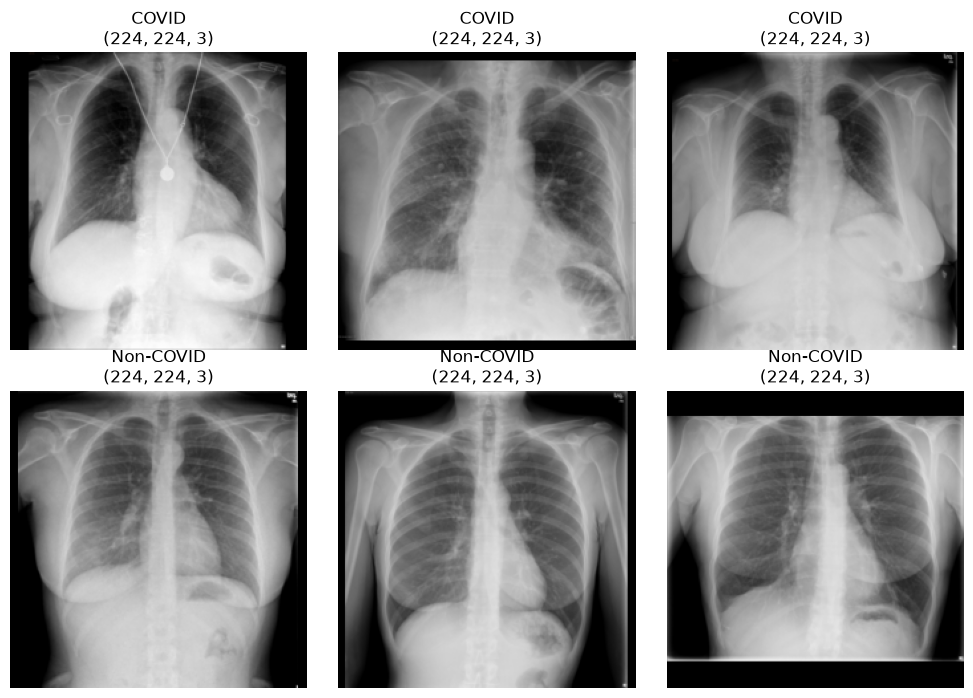

Standardised output shape: (224, 224, 3)
Pixel range: 0.0 to 223.13038635253906


In [3]:
#STEP 3 VALIDATE SHARED RGB, RESIZE PREPROCESSING TO LATER COMBINE WITH DATASET1
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)

def load_base_image(filepath):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.cast(image, tf.float32)

    return tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE[0],
        target_width=IMG_SIZE[1],
        antialias=True
    )

samples = (
    dataset2_df
    .groupby("original_label", group_keys=False)
    .sample(n=3, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    image = load_base_image(row["filepath"]).numpy().astype("uint8")

    ax.imshow(image)
    ax.set_title(
        f'{row["original_label"]}\n{image.shape}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

test_image = load_base_image(dataset2_df.iloc[0]["filepath"])

print("Standardised output shape:", test_image.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(test_image)),
    "to",
    float(tf.reduce_max(test_image))
)

the size standardization is done. one good observation is do we need all the samples to be at the same anatomical crop? we shall run a controlled experiment later on if required. the actual crop should be of the full lungs from collarbones down to the lung bases.

In [4]:
dataset2_manifest = dataset2_df.merge(
    properties2_df[
        ["filepath", "mode", "width", "height", "aspect_ratio"]
    ],
    on="filepath",
    how="left",
    validate="one_to_one"
)

# Dataset 2 does not support the later 3-class task by itself
# because Non-COVID is not necessarily Healthy or Pneumonia.
dataset2_manifest["multiclass_target"] = pd.NA

assert len(dataset2_manifest) == 852
assert dataset2_manifest["filepath"].isna().sum() == 0
assert dataset2_manifest["mode"].isna().sum() == 0

print("Dataset 2 manifest shape:", dataset2_manifest.shape)

display(dataset2_manifest.head())

manifest_dir = base_path.parent / "manifests"
manifest_dir.mkdir(exist_ok=True)

dataset2_manifest_path = manifest_dir / "dataset2_clean_manifest.csv"

dataset2_manifest.to_csv(
    dataset2_manifest_path,
    index=False
)

print(f"\nSaved Dataset 2 manifest to:\n{dataset2_manifest_path}")

Dataset 2 manifest shape: (852, 10)


,filepath,filename,original_label,covid_target,source_dataset,mode,width,height,aspect_ratio,multiclass_target
0,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,0021a3ef8340e3c2a599843997e94c76.jpg,COVID,1,COVIDGR_1.0,L,2736,2448,1.1176,<NA>
1,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00960b9bd138047f3b868404aac7e531.jpg,COVID,1,COVIDGR_1.0,L,2724,2578,1.0566,<NA>
2,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00b05aa3cb325265b9ded3f1a9f704c8.jpg,COVID,1,COVIDGR_1.0,L,2720,2218,1.2263,<NA>
3,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,00f9707e0de334db70a7924a9de98368.jpg,COVID,1,COVIDGR_1.0,L,2728,2236,1.2200,<NA>
4,C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project...,0187b7c65ef69abd633c9bad6675dabf.jpg,COVID,1,COVIDGR_1.0,L,2644,2131,1.2407,<NA>



Saved Dataset 2 manifest to:
C:\Users\rosen\Documents\AIS\EDA_PSUPR_Project\manifests\dataset2_clean_manifest.csv
